# Práctica 2.2 · Regresión lineal simple y múltiple: ¿de qué depende el ingreso laboral?

Este cuaderno acompaña la clase «Regresión lineal simple y múltiple» y sigue su mismo recorrido:

1. Explorar los datos · 2. Separar entrenamiento y prueba · 3. **Regresión simple**: ingreso según años de educación · 4. Revisar los supuestos · 5. Transformar la Y: el logaritmo del ingreso · 6. **Regresión múltiple** con variables ficticias · 7. Multicolinealidad · 8. **Métricas**: MAE, RMSE, R² y R² ajustado contra una línea base · 9. Hiperparámetros: Ridge y Lasso

**Datos.** `datos/2-2-regresion-lineal.xlsx` tiene 800 personas ocupadas **simuladas con fines didácticos**, al estilo de la Gran Encuesta Integrada de Hogares (GEIH): edad, educación, experiencia, horas, formalidad, sexo, zona, sector, estrato e ingreso laboral mensual. El ingreso se generó con una ecuación de Mincer conocida, así que se puede comprobar si la regresión recupera los efectos «verdaderos».

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Cargar y explorar los datos

In [3]:
trab = pd.read_excel(DATOS / '2-2-regresion-lineal.xlsx', sheet_name='trabajadores')
diccionario = pd.read_excel(DATOS / '2-2-regresion-lineal.xlsx', sheet_name='diccionario')
print(trab.shape)
trab.head()

(800, 13)


,id_persona,ciudad,zona,sexo,edad,anos_educacion,nivel_educativo,experiencia,horas_semana,formal,sector,estrato,ingreso_mensual
0,1,Medellín,Urbana,Hombre,43,12,Técnico,25,52,Sí,Servicios,5,3075000
1,2,Bogotá,Urbana,Mujer,33,10,Bachillerato,17,63,No,Servicios,4,1274000
2,3,Bogotá,Urbana,Hombre,31,13,Técnico,12,41,Sí,Comercio,4,1554000
3,4,Cali,Rural,Hombre,44,11,Bachillerato,27,34,Sí,Servicios,4,1746000
4,5,Medellín,Urbana,Mujer,49,3,Primaria,40,50,No,Construcción,1,777000


In [4]:
diccionario

,variable,descripcion,tipo,unidad o valores
0,id_persona,Identificador de la persona,Entero,—
1,ciudad,Ciudad donde vive,Categórica nominal,6 ciudades
2,zona,Zona de residencia,Categórica (binaria),Urbana / Rural
3,sexo,Sexo de la persona,Categórica (binaria),Hombre / Mujer
4,edad,Edad,Numérica,años
5,anos_educacion,Años de educación aprobados,Numérica,años
6,nivel_educativo,Máximo nivel educativo alcanzado,Categórica ordinal,Primaria < … < Posgrado
7,experiencia,Experiencia laboral potencial (edad − educació...,Numérica,años
8,horas_semana,Horas trabajadas por semana,Numérica,horas
9,formal,Cotiza a seguridad social (empleo formal),Categórica (binaria),Sí / No


In [5]:
trab[['edad', 'anos_educacion', 'experiencia', 'horas_semana', 'estrato', 'ingreso_mensual']].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,800.000,39.201,10.513,18.000,32.000,39.000,46.000,65.000
anos_educacion,800.000,10.578,3.477,0.000,8.000,11.000,13.000,21.000
experiencia,800.000,22.624,10.701,6.000,15.000,22.000,30.000,53.000
horas_semana,800.000,45.998,9.038,18.000,40.000,46.000,52.000,72.000
estrato,800.000,3.854,1.271,1.000,3.000,4.000,5.000,6.000
ingreso_mensual,800.000,"1,402,060.000","793,754.582","238,000.000","828,750.000","1,201,500.000","1,792,000.000","6,025,000.000"


Son **800 personas** con 10,6 años de educación en promedio y 22,6 de experiencia potencial. El ingreso mensual va de 238.000 a 6.025.000 pesos; la **media (1.402.060) está por encima de la mediana (1.201.500)**: hay una cola de ingresos altos, típica de los datos de ingreso, que volverá a aparecer al revisar los residuos.

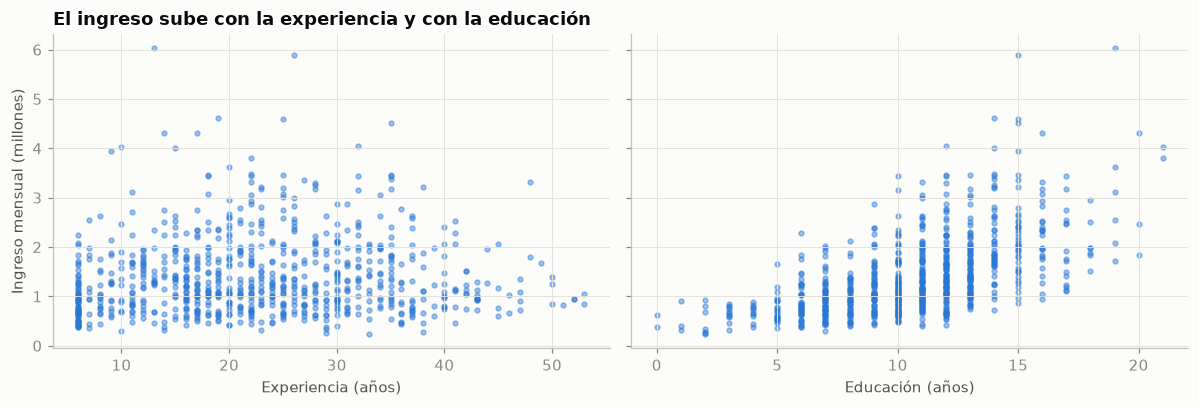

,experiencia,anos_educacion,horas_semana,estrato,ingreso_mensual
experiencia,1.000,-0.220,-0.050,-0.210,0.070
anos_educacion,-0.220,1.000,0.020,0.810,0.590
horas_semana,-0.050,0.020,1.000,0.000,0.080
estrato,-0.210,0.810,0.000,1.000,0.480
ingreso_mensual,0.070,0.590,0.080,0.480,1.000


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (col, nombre) in zip(axs, [('experiencia', 'Experiencia (años)'), ('anos_educacion', 'Educación (años)')]):
    ax.scatter(trab[col], trab['ingreso_mensual'] / 1e6, s=10, alpha=.45, color=AZUL)
    ax.set_xlabel(nombre)
axs[0].set_ylabel('Ingreso mensual (millones)')
axs[0].set_title('El ingreso sube con la experiencia y con la educación')
plt.tight_layout(); plt.show()
trab[['experiencia', 'anos_educacion', 'horas_semana', 'estrato', 'ingreso_mensual']].corr().round(2)

Las nubes muestran dos relaciones muy distintas. Con la **educación**, el ingreso sube con claridad (correlación 0,59). Con la **experiencia**, la nube casi no tiene pendiente (0,07). Ojo: experiencia y educación se relacionan negativamente (−0,22), porque quien estudia más años entra más tarde a trabajar. Y la educación va muy pegada al estrato (0,81), algo que importará en la sección 7.

## 2. Separar entrenamiento y prueba

Los coeficientes se estiman con el 80 % de las personas; el 20 % restante se guarda para medir el error con datos que el modelo no vio.

In [7]:
train, test = train_test_split(trab, test_size=0.2, random_state=SEMILLA)
print(f'Entrenamiento: {len(train)} personas · Prueba: {len(test)} personas')

Entrenamiento: 640 personas · Prueba: 160 personas


Quedan **640 personas para estimar** y **160 para evaluar**.

## 3. Regresión lineal simple: ingreso según años de educación

El modelo es $\hat{y} = \beta_0 + \beta_1 x$. Los **parámetros** $\beta_0$ (intercepto) y $\beta_1$ (pendiente) los estima el algoritmo de **mínimos cuadrados ordinarios** (MCO): la recta que hace mínima la suma de los residuos al cuadrado. Para leer coeficientes con su incertidumbre se usa `statsmodels`; para predecir, `scikit-learn` da lo mismo.

In [8]:
simple = smf.ols('ingreso_mensual ~ anos_educacion', data=train).fit()
pd.DataFrame({'coeficiente': simple.params, 'error estándar': simple.bse, 'IC 2,5 %': simple.conf_int()[0],
              'IC 97,5 %': simple.conf_int()[1], 'p': simple.pvalues}).assign(R2=[simple.rsquared, np.nan])

,coeficiente,error estándar,"IC 2,5 %","IC 97,5 %",p,R2
Intercept,"-21,741.926","81,718.895","-182,212.440","138,728.587",0.790,0.347
anos_educacion,"135,217.662","7,345.333","120,793.711","149,641.614",0.000,NaN


La recta estimada es **ingreso = −21.742 + 135.218 × años de educación**. Cada año adicional de educación se asocia, en promedio, con **135.218 pesos más de ingreso mensual**, con un intervalo de 95 % entre 120.794 y 149.642 pesos (p < 0,001). El intercepto negativo no se interpreta: diría que alguien sin un solo año de estudio gana menos de cero. Es una extrapolación fuera de los datos, y por eso β₀ casi nunca tiene lectura sustantiva. El modelo explica el **34,7 %** de la variación del ingreso en entrenamiento (R²).

In [9]:
x = train['anos_educacion']; y = train['ingreso_mensual']
b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = y.mean() - b1 * x.mean()
lr = LinearRegression().fit(train[['anos_educacion']], y)
print(f'A mano:        β0 = {b0:,.0f}   β1 = {b1:,.0f}')
print(f'scikit-learn:  β0 = {lr.intercept_:,.0f}   β1 = {lr.coef_[0]:,.0f}')
print(f'Predicción para 11 años de educación (bachiller): {lr.predict(pd.DataFrame({"anos_educacion": [11]}))[0]:,.0f} pesos')

A mano:        β0 = -21,742   β1 = 135,218
scikit-learn:  β0 = -21,742   β1 = 135,218
Predicción para 11 años de educación (bachiller): 1,465,652 pesos


Las fórmulas de mínimos cuadrados hechas a mano, $\beta_1 = \frac{\sum (x-\bar x)(y-\bar y)}{\sum (x-\bar x)^2}$ y $\beta_0 = \bar y - \beta_1 \bar x$, dan **exactamente lo mismo** que `scikit-learn`: no hay magia, solo esas dos cuentas. Para alguien con 11 años de educación (bachiller), el modelo predice **1.465.652 pesos**.

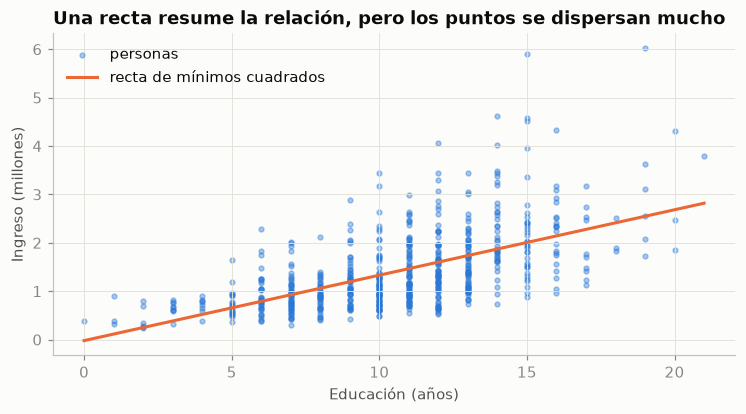

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(x, y / 1e6, s=10, alpha=.4, color=AZUL, label='personas')
xx = np.linspace(x.min(), x.max(), 50)
ax.plot(xx, (b0 + b1 * xx) / 1e6, color=NARANJA, label='recta de mínimos cuadrados')
ax.set_xlabel('Educación (años)'); ax.set_ylabel('Ingreso (millones)')
ax.set_title('Una recta resume la relación, pero los puntos se dispersan mucho'); ax.legend()
plt.show()

La recta capta la tendencia, pero los puntos se abren en abanico: a más educación, más dispersión del ingreso. Ese abanico es una pista de que la varianza no es constante, lo que se revisa a continuación.

## 4. Revisar los supuestos con los residuos

La regresión lineal supone (LINE): **L**inealidad, **I**ndependencia de los errores, **N**ormalidad de los errores e **E**qual varianza (homocedasticidad). Se revisan mirando los residuos $e = y - \hat{y}$.

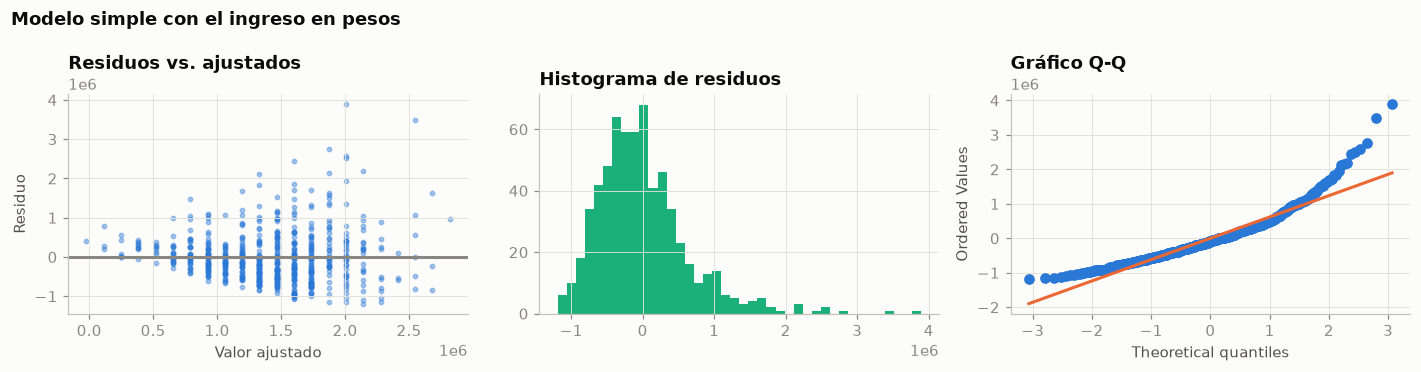

Asimetría de los residuos: 1.51


In [11]:
def diagnostico(modelo, titulo):
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
    axs[0].scatter(modelo.fittedvalues, modelo.resid, s=8, alpha=.4, color=AZUL); axs[0].axhline(0, color=GRIS)
    axs[0].set_xlabel('Valor ajustado'); axs[0].set_ylabel('Residuo'); axs[0].set_title('Residuos vs. ajustados')
    axs[1].hist(modelo.resid, bins=40, color=AQUA); axs[1].set_title('Histograma de residuos')
    stats.probplot(modelo.resid, plot=axs[2]); axs[2].set_title('Gráfico Q-Q')
    axs[2].get_lines()[0].set_color(AZUL); axs[2].get_lines()[1].set_color(NARANJA)
    plt.suptitle(titulo, x=.01, ha='left', fontweight='bold'); plt.tight_layout(); plt.show()
    print(f'Asimetría de los residuos: {stats.skew(modelo.resid):.2f}')

diagnostico(simple, 'Modelo simple con el ingreso en pesos')

Los residuos del modelo en pesos violan dos supuestos. El gráfico de residuos contra ajustados tiene forma de **embudo** (heterocedasticidad), y el histograma y el Q-Q muestran una cola larga a la derecha (**asimetría 1,51**): los errores no son normales. Los coeficientes siguen siendo útiles para predecir, pero sus errores estándar e intervalos no son confiables.

## 5. Transformar la Y: el logaritmo del ingreso

En economía laboral el ingreso casi siempre se modela en logaritmo (la ecuación de Mincer). Así los coeficientes se leen en **porcentaje**: un $\beta$ de 0,03 significa, aproximadamente, un 3 % más de ingreso por unidad de X.

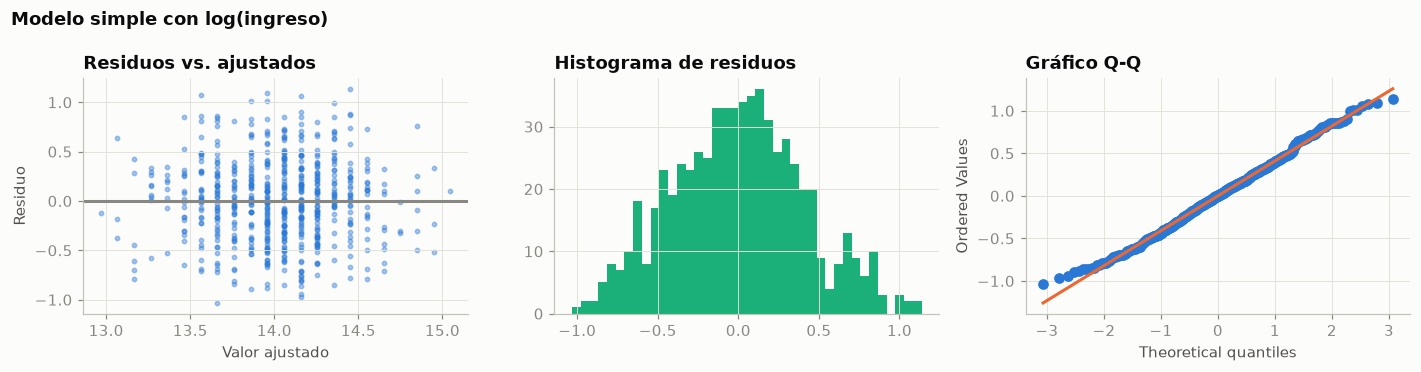

Asimetría de los residuos: 0.11
Cada año de educación: 10.4% más de ingreso, en promedio (R² = 0.415)


In [12]:
train = train.assign(log_ingreso=np.log(train['ingreso_mensual']))
test = test.assign(log_ingreso=np.log(test['ingreso_mensual']))
simple_log = smf.ols('log_ingreso ~ anos_educacion', data=train).fit()
diagnostico(simple_log, 'Modelo simple con log(ingreso)')
b = simple_log.params['anos_educacion']
print(f'Cada año de educación: {np.expm1(b):.1%} más de ingreso, en promedio (R² = {simple_log.rsquared:.3f})')

Con el **logaritmo del ingreso** el embudo se cierra, el histograma se vuelve casi simétrico (**asimetría 0,11**) y los puntos del Q-Q caen sobre la diagonal. Además, la lectura mejora: **cada año de educación se asocia con un 10,4 % más de ingreso**. El R² sube a 0,415 (en escala logarítmica). Es la misma idea de la situación 3 del mazo de ingeniería: transformar una variable con cola larga.

## 6. Regresión lineal múltiple

$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$. Cada $\beta_j$ es el cambio esperado en Y cuando $x_j$ sube una unidad **y las demás variables se mantienen constantes**. Las variables de texto entran como **variables ficticias** (0/1): cada una se compara con una categoría de referencia (aquí: hombre, zona urbana, empleo informal). La experiencia entra también al cuadrado para captar que el ingreso crece cada vez menos con los años.

In [13]:
formula = 'log_ingreso ~ anos_educacion + experiencia + I(experiencia**2) + horas_semana + C(sexo) + C(zona, Treatment("Urbana")) + C(formal)'
multiple = smf.ols(formula, data=train).fit()
tabla = pd.DataFrame({'coeficiente': multiple.params, 'efecto %': (np.expm1(multiple.params) * 100).where(multiple.params.index != 'Intercept'),
                      'IC 2,5 %': multiple.conf_int()[0], 'IC 97,5 %': multiple.conf_int()[1], 'p': multiple.pvalues})
tabla

,coeficiente,efecto %,"IC 2,5 %","IC 97,5 %",p
Intercept,12.551,NaN,12.338,12.764,0.000
C(sexo)[T.Mujer],-0.143,-13.353,-0.202,-0.085,0.000
"C(zona, Treatment(""Urbana""))[T.Rural]",-0.280,-24.384,-0.361,-0.198,0.000
C(formal)[T.Sí],0.142,15.307,0.077,0.208,0.000
anos_educacion,0.086,8.985,0.076,0.096,0.000
experiencia,0.029,2.921,0.018,0.040,0.000
I(experiencia ** 2),-0.000,-0.035,-0.001,-0.000,0.002
horas_semana,0.004,0.364,0.001,0.007,0.023


Con todas las variables, cada coeficiente se lee **manteniendo las demás constantes** y, como la Y está en logaritmo, en porcentaje:

- **Educación:** +9,0 % por año (IC de 0,076 a 0,096 en log).
- **Experiencia:** +2,9 % el primer año, y cada vez menos, porque el término al cuadrado es negativo (p = 0,002).
- **Horas:** +0,36 % por hora semanal (p = 0,023).
- **Ser mujer:** −13,4 % frente a un hombre con la misma educación, experiencia, horas, zona y formalidad.
- **Zona rural:** −24,4 % frente a la urbana.
- **Empleo formal:** +15,3 % frente al informal.

Como los datos se simularon con efectos conocidos (educación 0,085, mujer −0,13, formal 0,16, rural −0,22), se puede comprobar que **la regresión los recupera**: todos los valores verdaderos caen dentro de los intervalos, salvo el de la experiencia, que queda un poco por debajo.

In [14]:
sola = smf.ols('log_ingreso ~ experiencia', data=train).fit()
print(f'Experiencia sola:              {np.expm1(sola.params["experiencia"]):+.1%} por año   (R² = {sola.rsquared:.3f})')
print(f'Experiencia en el modelo múltiple: {np.expm1(multiple.params["experiencia"]):+.1%} por año (con educación y demás constantes)')
print(f'Correlación entre experiencia y educación: {train["experiencia"].corr(train["anos_educacion"]):.2f}')

Experiencia sola:              +0.2% por año   (R² = 0.002)
Experiencia en el modelo múltiple: +2.9% por año (con educación y demás constantes)
Correlación entre experiencia y educación: -0.24


Aquí está una de las lecciones más importantes de la regresión múltiple. **Sola, la experiencia parece no servir:** +0,2 % por año y R² de 0,002. **Con la educación en el modelo, vale +2,9 % por año.** La razón es que las dos están relacionadas (−0,24): quienes tienen más experiencia suelen haber estudiado menos, y en la regresión simple el efecto negativo de esa menor educación tapa el positivo de la experiencia. Es el **sesgo por variable omitida**: un coeficiente cambia cuando entra o sale otra X relacionada con él.

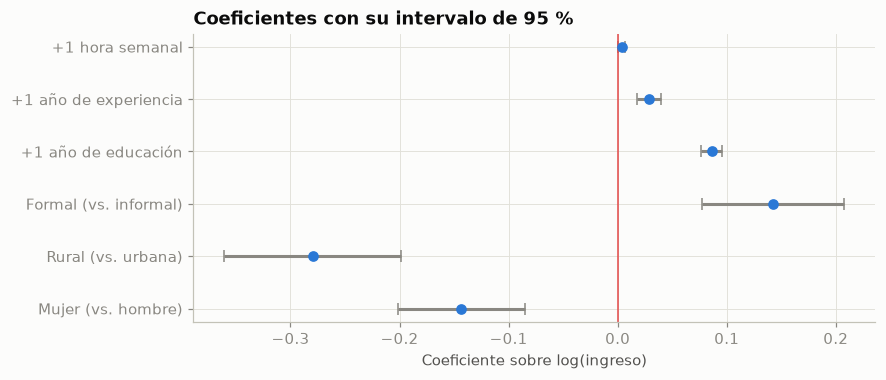

In [15]:
coefs = tabla.drop(index=['Intercept', 'I(experiencia ** 2)'])
nombres = {'anos_educacion': '+1 año de educación', 'experiencia': '+1 año de experiencia', 'horas_semana': '+1 hora semanal',
           'C(sexo)[T.Mujer]': 'Mujer (vs. hombre)', 'C(zona, Treatment("Urbana"))[T.Rural]': 'Rural (vs. urbana)', 'C(formal)[T.Sí]': 'Formal (vs. informal)'}
coefs = coefs.rename(index=nombres)
fig, ax = plt.subplots(figsize=(8, 3.4))
yv = np.arange(len(coefs))
ax.errorbar(coefs['coeficiente'], yv, xerr=[coefs['coeficiente'] - coefs['IC 2,5 %'], coefs['IC 97,5 %'] - coefs['coeficiente']],
            fmt='o', color=AZUL, ecolor=GRIS, capsize=4)
ax.axvline(0, color=ROJO, lw=1); ax.set_yticks(yv, coefs.index); ax.set_xlabel('Coeficiente sobre log(ingreso)')
ax.set_title('Coeficientes con su intervalo de 95 %'); plt.show()

El gráfico resume la tabla: cada punto es un coeficiente y la línea su intervalo de 95 %. **Ningún intervalo cruza el cero**, así que todos los efectos son distintos de cero con un 95 % de confianza. Los más grandes en magnitud son la zona rural (negativo) y la formalidad (positivo).

## 7. Multicolinealidad: cuando dos X cuentan casi lo mismo

El estrato y la educación van muy juntos. Si los dos entran al modelo, la regresión no sabe a cuál atribuirle el efecto: los coeficientes se vuelven inestables y sus errores estándar crecen. El **factor de inflación de la varianza (VIF)** lo mide; por encima de 5 o 10 hay que preocuparse.

In [16]:
X_vif = sm.add_constant(train[['anos_educacion', 'experiencia', 'horas_semana', 'estrato']])
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])], index=X_vif.columns[1:], name='VIF')
con_estrato = smf.ols(formula + ' + estrato', data=train).fit()
comparar = pd.DataFrame({'sin estrato': [multiple.params['anos_educacion'], multiple.bse['anos_educacion']],
                         'con estrato': [con_estrato.params['anos_educacion'], con_estrato.bse['anos_educacion']]},
                        index=['coef. educación', 'error estándar'])
display(vif.to_frame()); comparar

,VIF
anos_educacion,2.785
experiencia,1.067
horas_semana,1.003
estrato,2.776


,sin estrato,con estrato
coef. educación,0.086,0.087
error estándar,0.005,0.007


Aunque educación y estrato tienen una correlación de 0,81, el **VIF es 2,79 y 2,78**: por debajo del umbral de 5, así que la multicolinealidad es moderada. Su efecto se ve igual en el error estándar de la educación, que **sube de 0,005 a 0,007 (un 40 % más)** al meter el estrato, aunque el coeficiente casi no cambia (0,086 → 0,087). Con más colinealidad, los coeficientes empezarían a moverse de un lado a otro y a perder significancia.

## 8. Métricas de desempeño

Se evalúan cuatro modelos **con los datos de prueba**, siempre en pesos para que el error se entienda:

- **Línea base:** predecir para todos el ingreso promedio de entrenamiento.
- **Simple:** ingreso según experiencia.
- **Simple en log:** log(ingreso) según experiencia (se vuelve a pesos con la exponencial).
- **Múltiple en log:** todas las variables de la sección 6.

| Métrica | Fórmula | Se lee como |
|---|---|---|
| MAE | $\frac{1}{n}\sum |y-\hat y|$ | error típico, en pesos |
| RMSE | $\sqrt{\frac{1}{n}\sum (y-\hat y)^2}$ | error en pesos que castiga más los errores grandes |
| R² | $1-\frac{\sum (y-\hat y)^2}{\sum (y-\bar y)^2}$ | proporción de la variación que el modelo explica, frente a predecir la media |
| R² ajustado | $1-(1-R^2)\frac{n-1}{n-k-1}$ | R² que descuenta el número de variables $k$ |

In [17]:
def metricas(y, yhat, k):
    n = len(y); r2 = r2_score(y, yhat)
    return {'MAE': mean_absolute_error(y, yhat), 'RMSE': root_mean_squared_error(y, yhat), 'R²': r2,
            'R² ajustado': 1 - (1 - r2) * (n - 1) / (n - k - 1)}

yte = test['ingreso_mensual']
pred = {
    'Línea base (media)': (np.full(len(test), train['ingreso_mensual'].mean()), 0),
    'Simple (educación)': (simple.predict(test), 1),
    'Simple en log': (np.exp(simple_log.predict(test)), 1),
    'Múltiple en log': (np.exp(multiple.predict(test)), multiple.df_model),
}
resultados = pd.DataFrame({m: metricas(yte, p, k) for m, (p, k) in pred.items()}).T
resultados.round({'MAE': 0, 'RMSE': 0, 'R²': 3, 'R² ajustado': 3})

,MAE,RMSE,R²,R² ajustado
Línea base (media),"595,700.000","766,228.000",-0.001,-0.001
Simple (educación),"493,188.000","621,519.000",0.341,0.337
Simple en log,"461,071.000","617,028.000",0.351,0.347
Múltiple en log,"406,045.000","536,612.000",0.509,0.486


**La línea base define qué es un buen modelo.** Predecir siempre la media se equivoca en promedio por **595.700 pesos** (R² ≈ 0).

| Modelo | MAE (pesos) | RMSE (pesos) | R² |
|---|---|---|---|
| Simple con educación | 493.188 | 621.519 | 0,341 |
| Simple en log | 461.071 | 617.028 | 0,351 |
| Múltiple en log | **406.045** | **536.612** | **0,509** (ajustado 0,486) |

Con la simple, el MAE baja a 493.188. Con el log, a 461.071. **La múltiple lo baja a 406.045 pesos**: un error 32 % menor que el de la línea base. El RMSE es siempre mayor que el MAE porque eleva al cuadrado y pesa más los errores grandes, como los de los ingresos altos.

In [18]:
r2_train = {'Simple en log': simple_log.rsquared, 'Múltiple en log': multiple.rsquared}
print('R² en entrenamiento (escala de la Y de cada modelo):', {k: round(v, 3) for k, v in r2_train.items()})
# R² ajustado frente a R²: ¿qué pasa si se agregan 10 variables de puro ruido?
rng = np.random.default_rng(SEMILLA)
ruido = train.assign(**{f'ruido_{i}': rng.normal(size=len(train)) for i in range(10)})
con_ruido = smf.ols(formula + ' + ' + ' + '.join(f'ruido_{i}' for i in range(10)), data=ruido).fit()
print(f'Sin ruido:            R² = {multiple.rsquared:.4f}   R² ajustado = {multiple.rsquared_adj:.4f}')
print(f'Con 10 de ruido:      R² = {con_ruido.rsquared:.4f}   R² ajustado = {con_ruido.rsquared_adj:.4f}')

R² en entrenamiento (escala de la Y de cada modelo): {'Simple en log': np.float64(0.415), 'Múltiple en log': np.float64(0.534)}
Sin ruido:            R² = 0.5336   R² ajustado = 0.5284
Con 10 de ruido:      R² = 0.5406   R² ajustado = 0.5281


R² y R² ajustado responden preguntas distintas. En entrenamiento, el R² de la múltiple (0,534) supera al de la simple (0,415). Pero **el R² nunca baja al agregar variables**, aunque sean ruido puro. Al meter 10 columnas de números aleatorios, el R² sube de 0,5336 a 0,5406, mientras que **el R² ajustado baja de 0,5284 a 0,5281**: descuenta las variables que no aportan. Para comparar modelos con distinto número de X, se usa el ajustado.

## 9. ¿Y los hiperparámetros?

La regresión por mínimos cuadrados **no tiene hiperparámetros** que ajustar: dados los datos, la recta óptima es una sola. Sí los tienen sus versiones **regularizadas**:

- **Ridge** (penalización L2) encoge todos los coeficientes hacia cero.
- **Lasso** (penalización L1) puede llevar algunos exactamente a cero (selecciona variables).

El hiperparámetro es **λ** (`alpha` en scikit-learn): cuánto se castiga la complejidad. Se elige con validación cruzada, nunca con la prueba. Para que la penalización sea justa, las variables se estandarizan antes.

In [19]:
X_cols = ['anos_educacion', 'experiencia', 'horas_semana', 'estrato']
def matriz(d):
    X = d[X_cols].copy()
    X['experiencia2'] = d['experiencia'] ** 2
    X['mujer'] = (d['sexo'] == 'Mujer').astype(int); X['rural'] = (d['zona'] == 'Rural').astype(int)
    X['formal'] = (d['formal'] == 'Sí').astype(int)
    # candidatas que en estos datos no tienen efecto: ciudad y sector (Lasso debería descartarlas)
    X = X.join(pd.get_dummies(d[['ciudad', 'sector']], drop_first=True, dtype=int))
    return X
Xtr, Xte = matriz(train), matriz(test)
print(Xtr.shape[1], 'variables:', ', '.join(Xtr.columns))
cv = KFold(5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo, rejilla in [('Ridge', Ridge(), np.logspace(-3, 3, 25)), ('Lasso', Lasso(max_iter=20000), np.logspace(-4, -1, 25))]:
    busqueda = GridSearchCV(make_pipeline(StandardScaler(), modelo), {modelo.__class__.__name__.lower() + '__alpha': rejilla},
                            cv=cv, scoring='neg_root_mean_squared_error').fit(Xtr, train['log_ingreso'])
    mejor = busqueda.best_estimator_
    coef = mejor[-1].coef_
    p = np.exp(mejor.predict(Xte))
    filas.append({'modelo': nombre, 'λ elegido': busqueda.best_params_[modelo.__class__.__name__.lower() + '__alpha'],
                  'coeficientes en cero': int((np.abs(coef) < 1e-10).sum()), **metricas(yte, p, Xtr.shape[1])})
    if nombre == 'Lasso': fuera = list(Xtr.columns[np.abs(coef) < 1e-10])
ols_mat = LinearRegression().fit(Xtr, train['log_ingreso'])
filas.append({'modelo': 'MCO (sin λ)', 'λ elegido': 0, 'coeficientes en cero': 0, **metricas(yte, np.exp(ols_mat.predict(Xte)), Xtr.shape[1])})
print('Lasso dejó en cero:', ', '.join(fuera) if fuera else 'ninguna')
pd.DataFrame(filas).set_index('modelo').round({'λ elegido': 4, 'MAE': 0, 'RMSE': 0, 'R²': 3, 'R² ajustado': 3})

17 variables: anos_educacion, experiencia, horas_semana, estrato, experiencia2, mujer, rural, formal, ciudad_Bogotá, ciudad_Bucaramanga, ciudad_Cali, ciudad_Medellín, ciudad_Tunja, sector_Comercio, sector_Construcción, sector_Industria, sector_Servicios


Lasso dejó en cero: estrato, experiencia2, ciudad_Bogotá, ciudad_Bucaramanga, ciudad_Medellín, ciudad_Tunja, sector_Construcción, sector_Servicios


,λ elegido,coeficientes en cero,MAE,RMSE,R²,R² ajustado
modelo,,,,,,
Ridge,5.623,0,"417,987.000","548,229.000",0.488,0.426
Lasso,0.010,8,"419,916.000","548,310.000",0.487,0.426
MCO (sin λ),0.000,0,"416,630.000","548,329.000",0.487,0.426


Con 17 variables (incluidas ciudad, sector y estrato, que en estos datos no tienen efecto propio), la validación cruzada eligió **λ = 5,6 para Ridge y λ = 0,010 para Lasso**. Lasso dejó **8 coeficientes en cero**: el estrato, cuatro ciudades, dos sectores y el término de experiencia al cuadrado. Este último sí tiene efecto, pero es pequeño y va muy junto a la experiencia, y Lasso tiende a quedarse con una de dos variables correlacionadas. En prueba, los tres modelos quedan prácticamente empatados (MAE de 416.630 a 419.916 pesos), y **peor que la múltiple de la sección 8 (406.045)**: agregar variables sin efecto empeoró la predicción. Con pocas variables y muchos datos, la regularización casi no cambia nada; su valor aparece cuando hay muchas X o pocas observaciones.

## Conclusiones

| Pregunta | Respuesta con estos datos |
|---|---|
| ¿Qué expresa el modelo simple? | ingreso = −21.742 + 135.218 × educación: +135.218 pesos por año de estudio |
| ¿Cómo se estiman β₀ y β₁? | Por mínimos cuadrados; las dos fórmulas a mano dan lo mismo que `scikit-learn` |
| ¿Se cumplen los supuestos? | En pesos no (embudo y asimetría 1,51); con log(ingreso) sí (asimetría 0,11) |
| ¿Qué agrega la múltiple? | Efectos «lo demás constante»: +9,0 % por año de educación, −13,4 % mujer, −24,4 % rural, +15,3 % formal |
| ¿Qué enseña la experiencia? | Sola no dice nada (+0,2 %); con la educación controlada vale +2,9 %: sesgo por variable omitida |
| ¿Cuánto mejora? | MAE en prueba: 595.700 (media) → 493.188 (simple) → **406.045 (múltiple)** |
| ¿Qué métrica usar? | MAE para hablar en pesos; RMSE si los errores grandes son graves; R² frente a la media; R² ajustado para comparar modelos con distinto número de X |
| ¿Hiperparámetros? | MCO no tiene; Ridge y Lasso tienen λ, que se elige con validación cruzada |

La regresión lineal es a la vez un modelo para **explicar** (coeficientes con intervalo e interpretación) y para **predecir** (métricas en prueba). En una investigación conviene reportar las dos caras.

## Retos

1. **Otra X en la simple.** Ajuste la regresión simple con `horas_semana` en lugar de la educación. ¿Cuánto vale el R²? ¿Por qué tan poco?
2. **Nivel educativo como categorías.** Reemplace `anos_educacion` por `C(nivel_educativo)`. ¿Cuánto más gana un universitario que alguien con primaria, con lo demás constante?
3. **Interacción.** Agregue `C(sexo):anos_educacion` al modelo múltiple. ¿La educación rinde lo mismo para hombres y mujeres?
4. **Métricas por grupo.** Calcule el MAE de la múltiple por separado para la zona rural y la urbana. ¿Dónde se equivoca más el modelo, y qué implicaría eso para una política?
5. **Lasso más fuerte.** Fije `alpha=0.05` en el Lasso. ¿Qué variables sobreviven? ¿Cuánto empeora el MAE?